# Первые шаги в PyTorch

Вы уже знаете, как обучаются модели в ML, но пока не писали нейросеть на PyTorch?
Давайте начнём с небольшого примера и разберём, что происходит в каждой строке
обучения. Сначала посмотрим на один шаг изменения весов, затем соберём полный
цикл, а в конце попробуем обучить сеть восстанавливать собственный вход.

Работать будем с двумя признаками: так данные можно нарисовать, а обучение
занимает всего несколько секунд. По пути познакомимся с тензорами, градиентами,
батчами и режимами работы слоёв.

**Как запустить:** откройте ноутбук в Google Colab или Kaggle Notebooks и выберите
**Run all / Выполнить все**. Данные создаются прямо в коде, скачивать файлы не нужно.
CPU достаточно. Используем обычные `torch`, `numpy`, `scikit-learn` и `matplotlib`.

Когда захотите повторить эксперимент с начала, перезапустите сессию и выполните
все ячейки заново. Иначе в памяти могут остаться веса уже обученной модели.


In [ ]:
import copy
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)  # маленьким сетям достаточно одного CPU-потока
device = torch.device("cpu")
print("PyTorch:", torch.__version__, "| device:", device)


PyTorch: 2.11.0+cpu | device: cpu


## 1. Сначала посмотрим на данные

Сгенерируем 600 точек, образующих два полумесяца. У каждой точки два признака
и метка класса — 0 или 1. Посмотрите на рисунок ниже: получится ли разделить
эти классы одной прямой? Из-за изгиба полумесяцев линейной модели будет непросто.
Чуть позже добавим в сеть нелинейность и посмотрим, как она справится.

Перед обучением сделаем знакомые по ML шаги: разделим данные на train и validation,
затем приведём признаки к сопоставимому масштабу. `StandardScaler.fit_transform`
вычисляет среднее и стандартное отклонение по train. Для validation используем
`transform` с уже найденными значениями. Если вызвать `fit` на всех данных,
информация из проверочной выборки попадёт в подготовку модели.

На train будем менять веса, а по validation — выбирать момент остановки.
Для независимой итоговой оценки обычно выделяют ещё и test, который не участвует
в подборе настроек. Здесь ограничимся двумя частями, чтобы сосредоточиться на
самом обучении; оценку на validation будем понимать с учётом этого выбора.


train: (450, 2) validation: (150, 2)


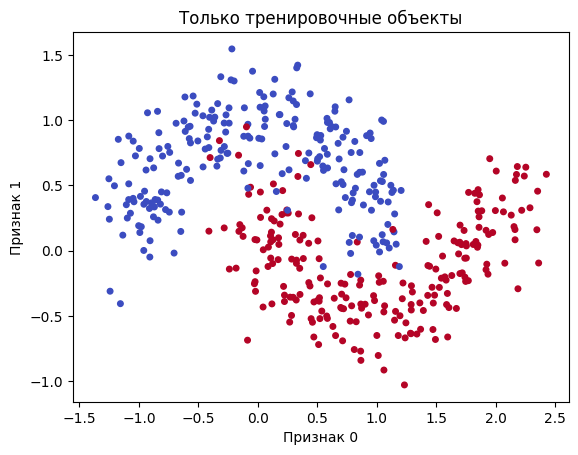

In [ ]:
X, y = make_moons(n_samples=600, noise=0.20, random_state=SEED)
X_train_raw, X_val_raw, y_train_np, y_val_np = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
scaler = StandardScaler()
X_train_np = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val_np = scaler.transform(X_val_raw).astype(np.float32)

assert scaler.n_samples_seen_ == len(X_train_raw)
print("train:", X_train_np.shape, "validation:", X_val_np.shape)
plt.scatter(X_train_raw[:, 0], X_train_raw[:, 1], c=y_train_np, cmap="coolwarm", s=16)
plt.xlabel("Признак 0")
plt.ylabel("Признак 1")
plt.title("Только тренировочные объекты")
plt.show()


## 2. Тензор: значения, форма, тип, устройство

Начнём с перевода массивов NumPy в тензоры. По виду они очень похожи, но с тензорами
PyTorch умеет строить граф вычислений и автоматически находить градиенты.
У тензора полезно сразу проверять три свойства: `shape`, `dtype` и `device`.

Пусть B — число объектов в батче, а D — число признаков. В нашем примере формы такие:

| Величина | Форма | Тип |
|---|---|---|
| Признаки `X` | `[B, D]` | `float32` |
| Метки `y` | `[B]` | `float32`, значения 0 или 1 |
| Выход последнего `Linear(..., 1)` | `[B, 1]` | `float32` |
| Логиты после `squeeze(-1)` | `[B]` | `float32` |

Почему метки вещественные, хотя классов всего два? Так устроен интерфейс
`BCEWithLogitsLoss`, который мы скоро используем. У другой функции потерь
требования могут отличаться. Модель и данные также должны быть на одном устройстве;
здесь всё оставим на CPU.

Обратите внимание на `squeeze(-1)`: он убирает последнюю размерность длины 1.
Если написать просто `squeeze()`, то при единственном объекте исчезнет и размерность
батча. Вместо вектора из одного числа получится скаляр — в конце проверим это сами.


In [ ]:
X_train = torch.from_numpy(X_train_np).to(device)
X_val = torch.from_numpy(X_val_np).to(device)
y_train = torch.tensor(y_train_np, dtype=torch.float32, device=device)
y_val = torch.tensor(y_val_np, dtype=torch.float32, device=device)

for name, tensor in {"X_train": X_train, "y_train": y_train}.items():
    print(name, "shape=", tuple(tensor.shape), "dtype=", tensor.dtype, "device=", tensor.device)
assert X_train.ndim == 2 and y_train.ndim == 1
assert len(X_train) == len(y_train)
assert torch.isfinite(X_train).all()
assert set(y_train.tolist()) == {0.0, 1.0}


X_train shape= (450, 2) dtype= torch.float32 device= cpu
y_train shape= (450,) dtype= torch.float32 device= cpu


## 3. Что выдаёт модель и как посчитать ошибку

Для начала возьмём `Linear(2, 1)` — знакомую линейную формулу `z = x @ w + b`.
На каждый объект она выдаёт одно число, **логит**. Он может быть отрицательным
или больше единицы. Функция sigmoid переводит его в диапазон (0, 1): например,
нулю соответствует 0.5. Это модельная оценка вероятности класса 1; насколько точно
она отражает реальные вероятности, нужно проверять отдельно.

Теперь хочется сравнить предсказания с метками. Для этого используем
`BCEWithLogitsLoss`: она принимает логиты и внутри численно устойчиво объединяет
sigmoid с бинарной кросс-энтропией. Поэтому передавать в неё уже вычисленный
sigmoid не нужно — иначе мы применим его дважды.

В ячейке ниже вы увидите логиты, значения sigmoid и одно число loss для всего батча.
Loss нужен для вычисления градиентов. Качество модели позже будем оценивать
по **Average Precision (AP)**: она показывает, насколько хорошо модель ставит
объекты класса 1 выше объектов класса 0. Для этого нужны непрерывные оценки
(scores), поэтому округлять предсказания до 0 и 1 мы не будем.


In [ ]:
probe = nn.Linear(2, 1).to(device)
criterion = nn.BCEWithLogitsLoss()
xb, yb = X_train[:8], y_train[:8]
logits = probe(xb).squeeze(-1)
probabilities = torch.sigmoid(logits)
loss = criterion(logits, yb)
assert logits.shape == yb.shape == (8,)
print("Логиты:", logits.detach().numpy().round(3))
print("Sigmoid:", probabilities.detach().numpy().round(3))
print("BCE loss:", round(loss.item(), 4))
print("sigmoid([-2, 0, 2]):", torch.sigmoid(torch.tensor([-2., 0., 2.])))


Логиты: [ 0.285 -0.463  0.636  0.422 -1.03   0.285 -1.115 -0.501]
Sigmoid: [0.571 0.386 0.654 0.604 0.263 0.571 0.247 0.377]
BCE loss: 0.9844
sigmoid([-2, 0, 2]): tensor([0.1192, 0.5000, 0.8808])


## 4. Один шаг обучения — под увеличительным стеклом

Пока модель ничего не выучила. Давайте сделаем ровно один шаг и сравним веса
до и после него. Возьмём простой оптимизатор SGD: он обновляет веса по формуле
`w_new = w_old - learning_rate * gradient`. Learning rate задаёт размер шага.
Оптимизатору передадим `probe.parameters()`, чтобы он знал, какие параметры менять.

1. `zero_grad()` очищает градиенты предыдущего шага: PyTorch по умолчанию их накапливает.
2. `probe(xb)` выполняет прямой проход и получает логиты.
3. Функция потерь сравнивает логиты с правильными ответами.
4. `backward()` вычисляет градиенты loss по параметрам. Веса в этот момент ещё прежние.
5. `step()` обновляет параметры с помощью найденных градиентов.

Чтобы сохранить старые веса для сравнения, используем `detach().clone()`:
`detach()` отделяет тензор от графа вычислений, а `clone()` делает независимую копию.
После запуска посмотрите на изменение весов: оно должно совпасть с градиентом,
умноженным на `-0.1`. Loss на этом батче помогает увидеть эффект шага; качество
на новых объектах будем проверять отдельно.


In [ ]:
optimizer_probe = torch.optim.SGD(probe.parameters(), lr=0.1)
probe.train()
weights_before = probe.weight.detach().clone()

optimizer_probe.zero_grad(set_to_none=True)
logits = probe(xb).squeeze(-1)
loss_before = criterion(logits, yb)
loss_before.backward()
gradient = probe.weight.grad.detach().clone()
assert torch.equal(probe.weight.detach(), weights_before), "backward не должен менять веса"
optimizer_probe.step()

with torch.no_grad():
    loss_after = criterion(probe(xb).squeeze(-1), yb)
weights_after = probe.weight.detach().clone()
assert torch.allclose(weights_after, weights_before - 0.1 * gradient)
assert not torch.equal(weights_before, weights_after)
print("Градиент весов:", gradient.numpy())
print("Изменение весов:", (weights_after - weights_before).numpy())
print(f"Loss этого батча: {loss_before.item():.4f} → {loss_after.item():.4f}")


Градиент весов: [[-0.04674443  0.6478128 ]]
Изменение весов: [[ 0.00467443 -0.06478131]]
Loss этого батча: 0.9844 → 0.9422


Давайте ненадолго остановимся: что случится, если забыть `step()`? А если убрать
`zero_grad()`? Попробуйте ответить, прежде чем читать дальше.

Без `step()` градиенты посчитаются, но веса останутся прежними — модель ничему
не научится. Без `zero_grad()` новые градиенты прибавятся к старым. Иногда это
делают специально, но здесь мы хотим обновлять веса по одному текущему батчу.
Заодно видно, зачем нужны две отдельные операции: `backward()` вычисляет градиенты,
а `step()` использует их для обновления весов.


## 5. Как пройти по всем данным: batch, epoch и DataLoader

Один шаг мы разобрали. Теперь нужно повторить его для всей обучающей выборки.
**Батч** — группа объектов для одного обновления весов, а **эпоха** — один проход
по всем тренировочным объектам. У нас их 450: при `batch_size=64` получится
`ceil(450 / 64) = 8` шагов. В последнем батче останется всего 2 объекта.

Разбивать массивы вручную не будем. `TensorDataset` объединит признаки с метками,
а `DataLoader` выдаст их порциями. `shuffle=True` перемешивает тренировочные объекты
между эпохами, сохраняя каждую метку рядом с её признаками.

При оценке тоже важно не потерять соответствие меток и предсказаний. Сам порядок
объектов для AP неважен, если переставлять эти пары вместе. Ниже выведем формы
всех батчей и проверим наш расчёт числа шагов.


In [ ]:
BATCH_SIZE = 64
loader = DataLoader(
    TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
batch_shapes = [(tuple(x.shape), tuple(y.shape)) for x, y in loader]
print("Формы батчей:", batch_shapes)
print("Шагов в эпохе:", len(loader))
assert len(loader) == math.ceil(len(X_train) / BATCH_SIZE)


Формы батчей: [((64, 2), (64,)), ((64, 2), (64,)), ((64, 2), (64,)), ((64, 2), (64,)), ((64, 2), (64,)), ((64, 2), (64,)), ((64, 2), (64,)), ((2, 2), (2,))]
Шагов в эпохе: 8


## 6. Зачем нужны train(), eval() и no_grad()

Перед циклом обучения разберём ещё одну деталь: некоторые слои по-разному работают
при обучении и предсказании. Например, Dropout во время обучения случайно зануляет
часть входных значений, а остальные умножает на `1 / (1 - p)`. Так он меняет
активации, проходящие через слой. В режиме оценки значения проходят без изменений.

Режимы переключаются вызовами `model.train()` и `model.eval()`. Сам вызов `train()`
ещё не обучает сеть — для этого нужны шаги, которые мы разобрали выше.

А что делает `torch.no_grad()`? Он отключает запись операций для вычисления
градиентов и позволяет экономить память при оценке. Режим работы слоёв от этого
не меняется. Поэтому при предсказании обычно используем и `eval()`, и `no_grad()`.

Проверим разницу на векторе единиц. При `train()` и `p=0.5` на выходе Dropout будут
нули и двойки даже внутри `no_grad()`. При `eval()` останутся единицы, но без
`no_grad()` тензор всё ещё может требовать вычисления градиента.


In [ ]:
dropout = nn.Dropout(p=0.5)
activations = torch.ones(12, requires_grad=True)
dropout.train()
with torch.no_grad():
    during_train = dropout(activations)
dropout.eval()
during_eval = dropout(activations)
print("train + no_grad:", during_train)
print("eval без no_grad:", during_eval)
print("eval: вход всё ещё требует градиент?", during_eval.requires_grad)
assert torch.equal(during_eval, activations)
assert during_eval.requires_grad


train + no_grad: tensor([0., 0., 2., 2., 0., 0., 2., 0., 2., 0., 0., 2.])
eval без no_grad: tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.], requires_grad=True)
eval: вход всё ещё требует градиент? True


### BatchNorm: у слоя есть ещё и память

У BatchNorm различие режимов менее заметно, но тоже важно.
`BatchNorm1d(D)` во время обучения нормализует каждый из D признаков по текущему
батчу и по умолчанию обновляет `running_mean` и `running_var` — накопленные оценки
среднего и дисперсии. В режиме `eval()` он использует сохранённые оценки.
Так предсказание не требует заново оценивать статистики по проверочному батчу.

Давайте проверим: пропустим через слой тренировочный батч, запомним среднее,
а затем переключимся в `eval()` и подадим validation. Сохранённое среднее
должно остаться прежним. Обратите внимание, что первый проход обновляет его
даже внутри `no_grad()`: это состояние слоя, а не градиент.

Есть и практическая тонкость: для входа `[B, D]` BatchNorm в режиме обучения
требует больше одного объекта. Если в последнем батче остаётся один объект,
можно изменить размер батча или задать `drop_last=True`. Во втором случае
неполный батч будет пропущен. Для обычного линейного слоя такой проблемы нет.


In [ ]:
bn = nn.BatchNorm1d(X_train.shape[1]).to(device)
bn.train()
with torch.no_grad():
    _ = bn(X_train[:8])
running_after_train = bn.running_mean.clone()
assert bn.num_batches_tracked.item() == 1
bn.eval()
with torch.no_grad():
    _ = bn(X_val[:8])
assert torch.equal(bn.running_mean, running_after_train)
assert bn.num_batches_tracked.item() == 1
print("Running mean после train и eval:", bn.running_mean.cpu().numpy())


Running mean после train и eval: [-0.01953408  0.01468986]


## 7. Собираем собственную модель

Вернёмся к нашим полумесяцам. Одного линейного слоя мало для изогнутой границы,
поэтому соберём MLP размера `2 → 16 → 1`: два входных признака, скрытый слой
из 16 нейронов и один выходной логит. Между линейными слоями поставим ReLU.
Именно она добавит нелинейность: без неё два линейных слоя снова свелись бы к одному.

Модель оформим как наследника `nn.Module`. В `__init__` создадим слои, а в `forward`
опишем, как данные проходят через них. Здесь они идут друг за другом, поэтому
удобно объединить их в `nn.Sequential`. Когда мы пишем `model(x)`, PyTorch вызывает
`forward`, а через `model.parameters()` оптимизатор получает параметры всех
зарегистрированных слоёв.

На выходе оставим форму `[B, 1]`; перед вычислением BCE будем убирать последнюю
размерность через `squeeze(-1)`. Ниже создаётся новая модель. Маленький `probe`,
на котором мы изучали один шаг, свою задачу уже выполнил.


In [ ]:
class TinyMLP(nn.Module):
    def __init__(self, input_dim=2, hidden_dim=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(SEED)
model = TinyMLP(input_dim=X_train.shape[1]).to(device)
print(model)
print("Обучаемых параметров:", sum(p.numel() for p in model.parameters()))
assert model(X_train[:3]).shape == (3, 1)


TinyMLP(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Обучаемых параметров: 65


## 8. Обучаем сеть и выбираем момент остановки

Теперь соберём знакомые действия в цикл. В каждом батче будут очистка градиентов,
прямой проход, loss, `backward()` и `step()`. После каждой эпохи переключимся
в `eval()` и измерим loss на train и validation, а также AP на validation.
Так обе кривые loss будут получены в одинаковом режиме работы модели.

Вместо SGD возьмём `AdamW`: он подстраивает масштаб обновлений для разных параметров.
`lr` по-прежнему задаёт базовый размер шага. Параметр `weight_decay` дополнительно
немного уменьшает веса. В AdamW это отдельная операция, которая в общем случае
не равнозначна добавлению L2-штрафа к loss. Насколько она полезна и какой выбрать
коэффициент, проверяют по validation.

Когда остановиться? Будем сохранять модель всякий раз, когда validation AP
улучшается. Если улучшения нет 10 эпох подряд, завершим цикл — это **early stopping**.
После него загрузим лучшие сохранённые веса: последняя эпоха не обязательно лучшая.

Для чекпоинтинга используем `copy.deepcopy(model.state_dict())`. Без копирования тензоры
в словаре продолжили бы меняться вместе с моделью. Такого чекпоинта достаточно для
предсказаний; для возобновления обучения стоило бы сохранить и состояние оптимизатора.

При запуске посмотрите, одинаково ли меняются loss и AP. Мы учим сеть уменьшать
дифференцируемый loss, но выбираем эпоху по качеству ранжирования — эти две величины
не обязаны улучшаться синхронно.


In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=0.01, weight_decay=1e-4)
train_loader = DataLoader(
    TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
history = {"train_loss": [], "val_loss": [], "val_ap": []}
best_val_ap, best_state, best_epoch = -1.0, None, None
patience, epochs_without_improvement = 10, 0

for epoch in range(1, 61):
    model.train()
    for xb, yb in train_loader:
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb).squeeze(-1)
        assert logits.shape == yb.shape
        loss = criterion(logits, yb)
        assert torch.isfinite(loss), "Проверьте входы и learning rate"
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        train_loss = criterion(model(X_train).squeeze(-1), y_train).item()
        val_logits = model(X_val).squeeze(-1)
        val_loss = criterion(val_logits, y_val).item()
        val_scores = torch.sigmoid(val_logits).cpu().numpy()
    val_ap = average_precision_score(y_val_np, val_scores)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_ap"].append(val_ap)
    if val_ap > best_val_ap:
        best_val_ap = val_ap
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
    if epoch == 1 or epoch % 10 == 0:
        print(f"Эпоха {epoch:2d}: loss={train_loss:.4f}, val_loss={val_loss:.4f}, AP={val_ap:.4f}")
    if epochs_without_improvement >= patience:
        print("Early stopping на эпохе", epoch)
        break

model.load_state_dict(best_state)
print("Восстановлена эпоха:", best_epoch)


Эпоха  1: loss=0.4881, val_loss=0.4802, AP=0.9326
Эпоха 10: loss=0.2845, val_loss=0.2890, AP=0.9421
Эпоха 20: loss=0.2563, val_loss=0.2681, AP=0.9479
Эпоха 30: loss=0.2203, val_loss=0.2221, AP=0.9645
Эпоха 40: loss=0.1904, val_loss=0.1946, AP=0.9824
Эпоха 50: loss=0.1580, val_loss=0.1550, AP=0.9856
Эпоха 60: loss=0.1408, val_loss=0.1401, AP=0.9864
Восстановлена эпоха: 57


## 9. Смотрим на результат

Сеть обучилась. Давайте сравним её AP с простой отправной точкой: всем объектам
выдадим одинаковый score. Такое предсказание никого не ставит выше остальных,
и его AP равна доле класса 1. Здесь классы сбалансированы, поэтому получится 0.5.
Сравните это число с AP обученной сети в выводе ниже.

Как устроена AP? Если двигаться по объектам от большего score к меньшему,
мы постепенно находим всё больше объектов класса 1. AP суммирует precision
с весами, равными приростам recall. В `average_precision_score` нет линейной
интерполяции между точками, поэтому это не площадь под PR-кривой, посчитанная
методом трапеций. Отдельный порог для превращения scores в классы здесь не нужен.

На левом графике будут кривые loss, на правом — AP. Если loss продолжает падать,
а AP стоит на месте, противоречия нет: значения предсказаний могут меняться,
сохраняя их порядок и группы равных scores. Вертикальная линия отмечает эпоху,
которую мы сохранили; итоговая AP должна совпасть с лучшей AP в истории.

Validation уже помогла нам выбрать эпоху, поэтому эта оценка не независима
от выбора модели. Для итоговой проверки понадобился бы отдельный test.
И ещё: наши полумесяцы — маленький сбалансированный пример. Высокая AP здесь
не обещает такого же результата на более сложных данных.


Validation AP выбранной эпохи: 0.9886; constant AP: 0.5000


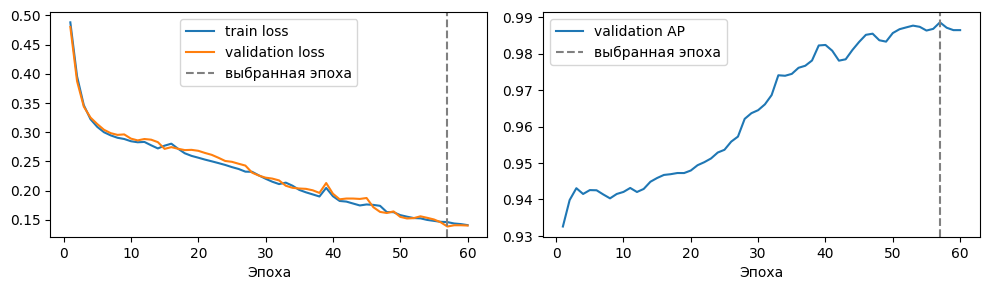

In [ ]:
model.eval()
with torch.no_grad():
    val_scores = torch.sigmoid(model(X_val).squeeze(-1)).cpu().numpy()
val_ap = average_precision_score(y_val_np, val_scores)
constant_ap = average_precision_score(y_val_np, np.zeros(len(y_val_np)))
assert np.isclose(constant_ap, y_val_np.mean())
assert np.isclose(val_ap, best_val_ap)
print(f"Validation AP выбранной эпохи: {val_ap:.4f}; constant AP: {constant_ap:.4f}")

epochs = np.arange(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(epochs, history["train_loss"], label="train loss")
axes[0].plot(epochs, history["val_loss"], label="validation loss")
axes[1].plot(epochs, history["val_ap"], label="validation AP")
for ax in axes:
    ax.axvline(best_epoch, color="gray", linestyle="--", label="выбранная эпоха")
    ax.set_xlabel("Эпоха")
    ax.legend()
plt.tight_layout()
plt.show()


## 10. Если что-то пошло не так

При первых экспериментах легко перепутать форму тензора или пропустить строку
в цикле. Начните с простых проверок — часто их достаточно, чтобы найти причину.

| Что наблюдаем | Куда сначала посмотреть | Что попробовать |
|---|---|---|
| Ошибка несовпадения размеров | `X.shape`, `y.shape`, `logits.shape` | У `Linear` должно быть D входов; после `squeeze(-1)` формы logits и y должны быть `[B]` |
| Ошибка типа или устройства | `dtype` и `device` входов и параметров | Для нашего BCE используйте float32; перенесите модель и данные на одно устройство |
| Loss стал NaN/inf | Входы и масштабы признаков | Устраните NaN/inf в данных; попробуйте меньший lr |
| Train loss не уменьшается | Вызовы `backward()` и `step()`, параметры оптимизатора | Попробуйте обучиться на одном маленьком батче; проверьте lr |
| Train loss падает, validation ухудшается | Подготовка данных и режим оценки | Вернитесь к более ранней эпохе; затем попробуйте меньшую сеть или регуляризацию |
| Все scores почти одинаковые | Диапазон логитов, метки и обновление весов | Проверьте, меняются ли веса и есть ли в train оба класса |

У одного симптома может быть несколько причин. Меняйте что-то одно и записывайте,
что получилось: так будет понятно, какое действие помогло. Удачный вариант полезно
повторить с другими seed, чтобы проверить, не повезло ли нам с одним запуском.


## 11. Попробуйте сами

Перед запуском запишите, чего ожидаете. Сравнить своё предположение с выводом
ячейки часто полезнее, чем просто ещё раз прочитать код.

1. **Один объект.** Каковы формы логитов для `X_val[:1]` до и после `squeeze(-1)`?
   Что получится с `squeeze()` без аргумента?
2. **Размер батча.** Сколько шагов будет за эпоху при `batch_size=128` и 450 объектах?
   Сколько объектов останется в последнем батче?
3. **Режим оценки.** Достаточно ли `no_grad()`, чтобы выключить Dropout?
4. **Размер сети.** Скопируйте цикл обучения и создайте новую модель с 4 нейронами
   вместо 16, а также новый оптимизатор. При том же seed сравните кривые и AP.
   Что изменилось? Попробуйте объяснить результат именно этого опыта.
   Начните с новых весов: продолжение обучения старой сети даст другой эксперимент.
5. **AP и loss.** Может ли loss уменьшиться, а AP остаться прежней?
   Подумайте, что будет, если порядок scores и группы равных значений не изменятся.

Ниже — проверки первых двух заданий и пояснения к остальным.


In [ ]:
with torch.no_grad():
    one_output = model(X_val[:1])
assert one_output.shape == (1, 1)
assert one_output.squeeze(-1).shape == (1,)
assert one_output.squeeze().shape == ()  # скаляр: размерность батча потеряна

check_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128)
sizes = [len(yb) for _, yb in check_loader]
assert len(sizes) == 4 and sizes[-1] == 66
print("Формы для одного объекта:", one_output.shape, one_output.squeeze(-1).shape)
print("Батчи размера 128:", sizes)


Формы для одного объекта: torch.Size([1, 1]) torch.Size([1])
Батчи размера 128: [128, 128, 128, 66]


В первом задании `squeeze(-1)` оставляет вектор длины 1, а `squeeze()` превращает
его в скаляр. Во втором получаются четыре батча: 128, 128, 128 и 66 объектов.
Сверьте эти числа с выводом ячейки.

В третьем задании нужен `eval()`: `no_grad()` не выключает Dropout и не останавливает
обновление статистик BatchNorm в режиме обучения.

У опыта с четырьмя нейронами нет заранее обязательного победителя. Меньшей сети
может не хватить гибкости для границы классов, но результат зависит и от обучения.
Сравните обе кривые loss и validation AP, а затем повторите опыт с другим seed.

В пятом задании ответ — да. BCE зависит от значений логитов, а AP — от порядка
объектов и групп равных scores. Если порядок и эти группы не меняются, AP остаётся
прежней, даже когда loss уменьшается.

Теперь можно вернуться к циклу обучения и прочитать его целиком: от входного
батча до обновления весов и проверки качества. Если какая-то строка ещё вызывает
вопросы, попробуйте вывести формы и значения вокруг неё — теперь у вас есть
небольшой пример, на котором это легко проверить.
